# Gradient similarity

Pairwise similarity of FGSM input gradients between models, with the attacksv2 configuration system (grain = family/architecture/variant, `mean`/`most_similar`/`least_similar` aggregation, per-view blacklist, asymmetric row/column grains).

**Compute is decoupled from figures**: run `scripts/compute_gradient_similarity_cache.py` on the cluster (Discord-notified, resumable), sync `logs/GRADIENTS/` back, then run this notebook. Pair metrics include **all** models (blacklisted ones too); exclude per view via `model_blacklist=`/`blacklist_contains=` in the config.

Metrics (higher = more similar): `Sign Agreement` (most FGSM-relevant, random ~0.5), `Gradient Cosine`, `Saliency TopK Jaccard`, `Saliency Pearson`.

In [1]:
import sys
from pathlib import Path

# Add src/ to sys.path before importing analytics (required for Jupyter kernels).
_project_root = Path.cwd().resolve()
while _project_root != _project_root.parent and not (_project_root / "src" / "analytics").is_dir():
    _project_root = _project_root.parent
if not (_project_root / "src" / "analytics").is_dir():
    raise FileNotFoundError(
        "Could not find the project root (expected src/analytics/). "
        "Set the notebook working directory to the QB-PIER repo root."
    )
_src = _project_root / "src"
if str(_src) not in sys.path:
    sys.path.insert(0, str(_src))

from analytics.notebook_setup import notebook_paths

project_root, TRAINING_ROOT, ATTACK_EXPERIMENT_DIR, OUT, _src = notebook_paths("gradient_similarity", start=_project_root)

CACHE_DIR = project_root / "logs" / "GRADIENTS"  # synced from the cluster
METRICS = None        # None = all four similarity metrics; or e.g. ["Sign Agreement"]
RANKING_TOP_K = 3     # rows in the most/least-similar ranking tables
REBUILD_PAIRS = False # True = recompute the pair CSV from cached .pt gradients

## Crawl: cache state

Inspect what the cluster produced before loading anything: run metadata, cached models, and trained models still missing from the cache.

In [2]:
import json

from analytics.attacks.gradient_similarity import GRADIENTS_SUBDIR, safe_model_name

meta_path = CACHE_DIR / "meta.json"
if meta_path.exists():
    print(json.dumps(json.loads(meta_path.read_text(encoding="utf-8")), indent=2))
else:
    print(f"No meta.json under {CACHE_DIR} - run scripts/compute_gradient_similarity_cache.py")

cached = sorted(p.stem for p in (CACHE_DIR / GRADIENTS_SUBDIR).glob("*.pt")) if (CACHE_DIR / GRADIENTS_SUBDIR).is_dir() else []
trained = sorted(
    p.parent.relative_to(TRAINING_ROOT).as_posix()
    for p in TRAINING_ROOT.rglob(".model")
)
missing = [name for name in trained if safe_model_name(name) not in set(cached)]
print(f"\nCached gradients: {len(cached)} models | trained models: {len(trained)} | missing from cache: {len(missing)}")
for name in missing:
    print("  missing:", name)

{
  "timestamp": "2026-06-12T18:48:07",
  "model_logdir": "../Experiments/MODELS/ByModel",
  "dataset": "mnist",
  "n_samples": 512,
  "top_k_fraction": 0.1,
  "models_cached": 51,
  "models_computed": 51,
  "models_skipped_existing": 0,
  "models_failed": [],
  "pair_rows": 2601
}

Cached gradients: 51 models | trained models: 51 | missing from cache: 0


## Load: pair metrics

In [3]:
from analytics.attacks.gradient_similarity import load_gradient_pair_metrics

pair_df = load_gradient_pair_metrics(CACHE_DIR, rebuild=REBUILD_PAIRS)
print(f"{len(pair_df)} pair rows, {pair_df['Source Model'].nunique()} models, n_samples={pair_df['n_samples'].iloc[0]}")
pair_df.head()

2601 pair rows, 51 models, n_samples=512


,Source Model,Target Model,n_samples,top_k_fraction,Sign Agreement,Gradient Cosine,Saliency TopK Jaccard,Saliency Pearson
0,"Classical/convnet/conv_channels=[32,64],fc_siz...","Classical/convnet/conv_channels=[32,64],fc_siz...",512,0.1,1.000000,1.000000,1.000000,1.000000
1,"Classical/convnet/conv_channels=[32,64],fc_siz...","Classical/convnet/conv_channels=[8],fc_sizes=[10]",512,0.1,0.440808,0.149503,0.136341,0.281006
2,"Classical/convnet/conv_channels=[8],fc_sizes=[10]","Classical/convnet/conv_channels=[32,64],fc_siz...",512,0.1,0.440808,0.149503,0.136341,0.281006
3,"Classical/convnet/conv_channels=[32,64],fc_siz...","Classical/convnet/conv_channels=[8],fc_sizes=[32]",512,0.1,0.486547,0.204967,0.175412,0.341914
4,"Classical/convnet/conv_channels=[8],fc_sizes=[32]","Classical/convnet/conv_channels=[32,64],fc_siz...",512,0.1,0.486547,0.204967,0.175412,0.341914


## Generate: standard report

Per metric: matrix CSVs for every template (`variant_full` stays CSV-only - the variant heatmap is unreadable), heatmap figures for the family/architecture grains, and top-k most/least similar ranking tables at architecture grain. Outputs under `outputs/gradient_similarity/<metric>/`.

In [4]:
from analytics.attacks.gradient_similarity import (
    GRADSIM_METRICS,
    GRADSIM_TEMPLATES,
    run_gradient_similarity_report,
)

outputs = run_gradient_similarity_report(
    pair_df,
    out_root=OUT,
    metrics=METRICS or GRADSIM_METRICS,
    ranking_top_k=RANKING_TOP_K,
)
print(f"{len(outputs)} artifacts written under {OUT}")

52 artifacts written under C:\Users\fwilh\Desktop\QB-PIER\outputs\gradient_similarity


## Example: quantum variants (rows) vs all architectures (columns)

Asymmetric grains: `source_grain="variant"` + `source_family_filter="Quantum"` selects quantum variants as rows, `target_grain="architecture"` puts every architecture in the zoo as columns. Swap any grain/subset with `source_family_filter`, `selected_rows`, `selected_columns`, `source_contains`, or `model_blacklist`/`blacklist_contains` overrides.

target_group,Classical/CNN,Classical/MLP,Classical/MLPMixer,Classical/ResNet18,Hybrid/HPVQL,Hybrid/HQE,Hybrid/HQuanv,Hybrid/HVQL,Hybrid/HVQM,Quantum/VQM
source_group,,,,,,,,,,
"Quantum/vqm/n_qdepth=10,ansatz=basic",0.435490,0.425638,0.500446,0.387364,0.452361,0.474946,0.190835,0.455279,0.502870,0.475606
"Quantum/vqm/n_qdepth=10,ansatz=random,ratio_imprim=0.75",0.434261,0.426379,0.500421,0.387299,0.452917,0.475718,0.188005,0.453393,0.502151,0.475524
"Quantum/vqm/n_qdepth=10,ansatz=strong",0.441177,0.433109,0.502947,0.390829,0.455636,0.481951,0.192153,0.456492,0.510293,0.481290
"Quantum/vqm/n_qdepth=100,ansatz=strong",0.452538,0.446939,0.511980,0.390839,0.460924,0.481107,0.201366,0.460581,0.524730,0.494164
"Quantum/vqm/n_qdepth=200,ansatz=strong",0.456299,0.452531,0.511213,0.393487,0.461311,0.483087,0.205042,0.461549,0.525834,0.497012
"Quantum/vqm/n_qdepth=25,ansatz=basic",0.434043,0.423632,0.503149,0.389957,0.450994,0.474049,0.187869,0.453656,0.501994,0.475553
"Quantum/vqm/n_qdepth=25,ansatz=random,ratio_imprim=0.75",0.434277,0.427848,0.501938,0.389673,0.453233,0.475292,0.189815,0.454204,0.502634,0.477834
"Quantum/vqm/n_qdepth=25,ansatz=strong",0.443882,0.438854,0.506998,0.392541,0.456620,0.482664,0.196384,0.458006,0.512968,0.486566
"Quantum/vqm/n_qdepth=5,ansatz=basic",0.432595,0.422289,0.500984,0.389793,0.452830,0.477033,0.188258,0.453138,0.501812,0.473585


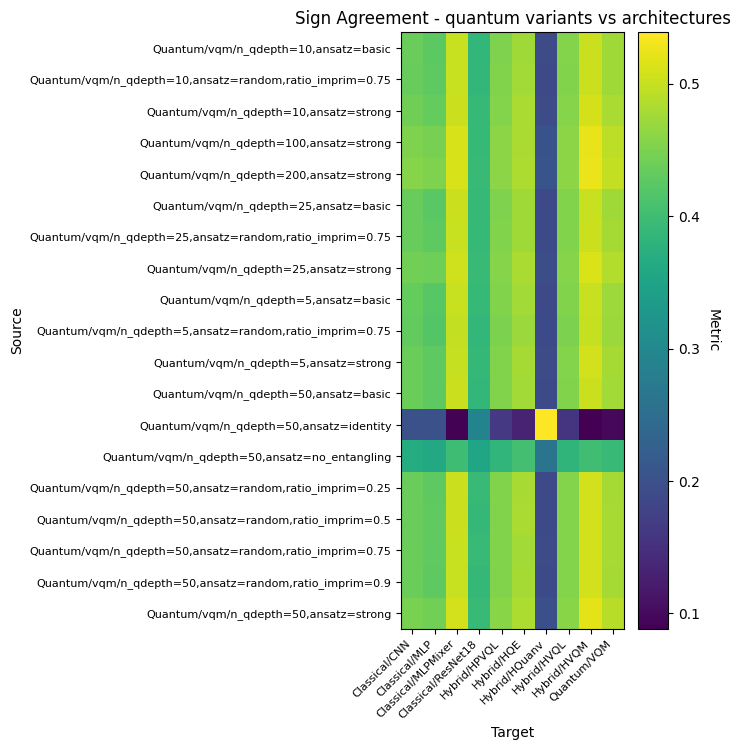

In [5]:
from analytics.attacks.gradient_similarity import get_gradsim_template
from analytics.attacks.transfer_role_tools import build_attack_matrix, plot_attack_matrix

cfg = get_gradsim_template("quantum_variants_vs_architectures", metric="Sign Agreement")
matrix = build_attack_matrix(pair_df, cfg)
fig, ax = plot_attack_matrix(matrix, title="Sign Agreement - quantum variants vs architectures")
matrix